In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Users\mersi\Documents\greenbootcamps\nitrate-groundwater-germany\.venv\Scripts\python.exe
Pandas: 3.0.5
NumPy: 2.5.2
Matplotlib: 3.11.1


# Hypothesis Testing

## Groundwater Nitrate in Germany: Spatial and Temporal Analysis (2012–2022)

This notebook evaluates the main hypotheses of the project using statistical methods and visual analysis.

In [1]:
import pandas as pd


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/powerbi_groundwater_nitrate.csv")

df.shape

(7311, 14)

In [3]:
from scipy.stats import spearmanr, kruskal

print("SciPy radi!")

SciPy radi!


## H1 – Long-term nitrate trend

**H0:** There is no systematic change in annual mean nitrate concentration between 2012 and 2022.

**H1:** Annual mean nitrate concentration decreases over time between 2012 and 2022.

In [4]:
yearly_mean = (
    df.groupby("Year")["Nitrate_mg_L"]
    .mean()
    .reset_index()
)

yearly_mean

,Year,Nitrate_mg_L
0,2012,40.814268
1,2013,41.671477
2,2014,41.338134
3,2015,39.667088
4,2016,38.718380
5,2017,36.554664
6,2018,36.953494
7,2019,36.781051
8,2020,37.413757
9,2021,35.158717


In [5]:
x = yearly_mean["Year"].to_numpy()
y = yearly_mean["Nitrate_mg_L"].to_numpy()

slope, intercept = np.polyfit(x, y, 1)

print("Slope:", slope)
print("Change per year:", round(slope, 3), "mg/L")

Slope: -0.6691904330324987
Change per year: -0.669 mg/L


In [6]:
# Permutation test for a negative temporal trend

rng = np.random.default_rng(42)

n_permutations = 10000
permuted_slopes = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled_y = rng.permutation(y)
    permuted_slopes[i] = np.polyfit(x, shuffled_y, 1)[0]

# One-sided p-value:
# H1 assumes a negative slope
p_value = (
    np.sum(permuted_slopes <= slope) + 1
) / (n_permutations + 1)

print("Observed slope:", round(slope, 3), "mg/L per year")
print("Permutation p-value:", round(p_value, 4))

Observed slope: -0.669 mg/L per year
Permutation p-value: 0.0002


### H1 Result

The average groundwater nitrate concentration shows a statistically significant
decreasing trend between 2012 and 2022.

The estimated linear trend is approximately **-0.669 mg/L per year**.
A permutation test with 10,000 permutations produced a **p-value of 0.0002**.

Since p < 0.05, the null hypothesis is rejected.

**Conclusion: H1 is supported. Groundwater nitrate concentrations decreased
significantly over the study period.**

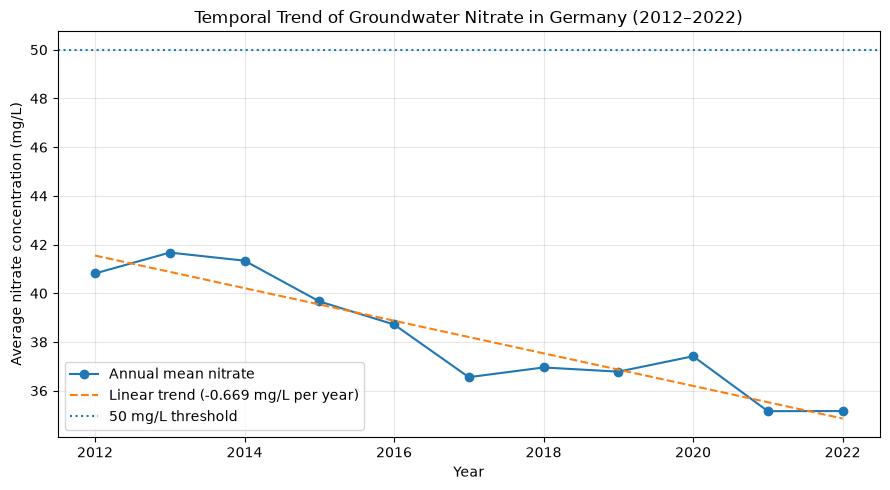

In [7]:
plt.figure(figsize=(9, 5))

# Yearly average nitrate
plt.plot(
    yearly_mean["Year"],
    yearly_mean["Nitrate_mg_L"],
    marker="o",
    label="Annual mean nitrate"
)

# Linear trend
trend_line = slope * x + intercept

plt.plot(
    yearly_mean["Year"],
    trend_line,
    linestyle="--",
    label=f"Linear trend ({slope:.3f} mg/L per year)"
)

plt.axhline(
    y=50,
    linestyle=":",
    label="50 mg/L threshold"
)

plt.xlabel("Year")
plt.ylabel("Average nitrate concentration (mg/L)")
plt.title("Temporal Trend of Groundwater Nitrate in Germany (2012–2022)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

H1: Groundwater nitrate concentrations decreased significantly between 2012 and 2022.
The average concentration decreased by approximately 0.67 mg/L per year (permutation test, p = 0.0002).

## H2 — Differences Between Federal States

**Hypothesis:** Groundwater nitrate concentrations differ significantly among German federal states.

In [8]:
df_powerbi = pd.read_csv("../data/processed/powerbi_groundwater_nitrate.csv")

print(df_powerbi.shape)
df_powerbi.head()

(7311, 14)


,StationCode,Year,NumberOfMeasurements,Nitrate_mg_L,StationName,GroundwaterBodyCode,GroundwaterBodyName,SamplingDepth_m,Longitude,Latitude,NitrateStatus,NitrateCategory,StateCode,FederalState
0,BB_25481088,2012,1,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
1,BB_25481088,2013,1,1.07,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
2,BB_25481088,2014,1,0.31,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
3,BB_25481088,2015,2,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg
4,BB_25481088,2016,1,0.16,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854,At or below 50 mg/L,Low (0-25 mg/L),BB,Brandenburg


In [9]:
state_summary = (
    df_powerbi
    .groupby("FederalState")["Nitrate_mg_L"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
    .round(2)
)

state_summary

,count,mean,median,std
FederalState,,,,
Bremen,12,80.11,101.58,48.80
Sachsen,368,60.34,51.00,48.04
Rheinland-Pfalz,372,58.06,50.08,51.17
Niedersachsen,1111,46.64,21.25,56.93
Schleswig-Holstein,439,45.19,32.74,48.00
Thüringen,338,45.05,37.70,35.94
Hessen,342,42.78,36.35,36.87
Sachsen-Anhalt,537,40.42,15.00,55.26
Nordrhein-Westfalen,574,37.97,22.42,47.33


In [11]:
import scipy.stats as stats

ImportError: DLL load failed while importing _biasedurn: An Application Control policy has blocked this file.

In [ ]:
# H2: Kruskal-Wallis test
# Test whether nitrate concentrations differ among federal states

groups = [
    group["Nitrate_mg_L"].dropna().values
    for _, group in df_powerbi.groupby("FederalState")
]

h_stat, p_value_h2 = stats.kruskal(*groups)

print("Kruskal-Wallis H statistic:", round(h_stat, 3))
print("p-value:", p_value_h2)

if p_value_h2 < 0.05:
    print("Result: Significant differences exist between federal states.")
else:
    print("Result: No statistically significant differences were detected.")

Kruskal-Wallis H statistic: 713.414
p-value: 3.5315451244822714e-143
Result: Significant differences exist between federal states.


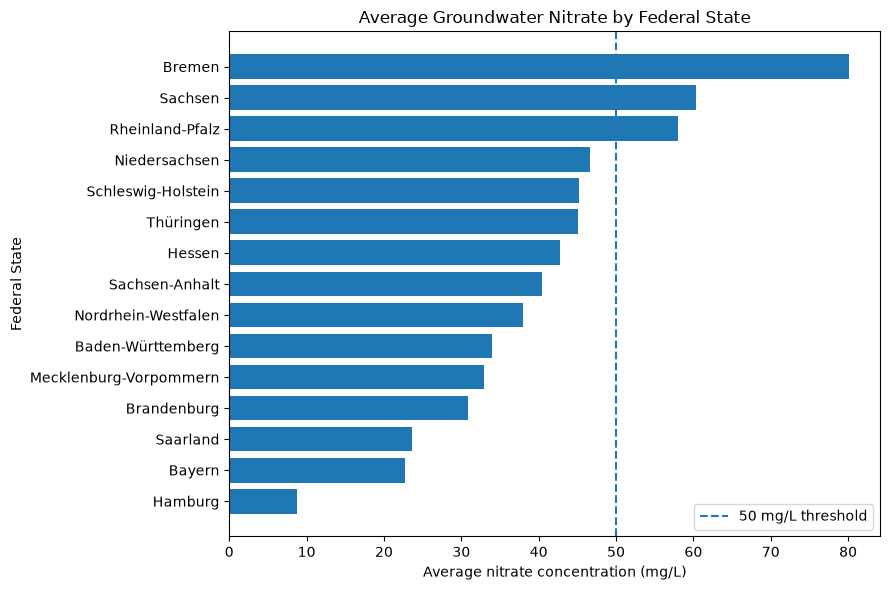

In [ ]:
state_means = (
    df_powerbi
    .groupby("FederalState")["Nitrate_mg_L"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 6))

plt.barh(
    state_means.index,
    state_means.values
)

plt.axvline(
    50,
    linestyle="--",
    label="50 mg/L threshold"
)

plt.xlabel("Average nitrate concentration (mg/L)")
plt.ylabel("Federal State")
plt.title("Average Groundwater Nitrate by Federal State")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
import matplotlib.pyplot as plt

print(df[["FederalState", "Nitrate_mg_L"]].head())
print(df["Nitrate_mg_L"].max())

  FederalState  Nitrate_mg_L
0  Brandenburg          0.15
1  Brandenburg          1.07
2  Brandenburg          0.31
3  Brandenburg          0.15
4  Brandenburg          0.16
776.32


C:\Users\mersi\AppData\Local\Temp\ipykernel_24676\2708796131.py:29: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


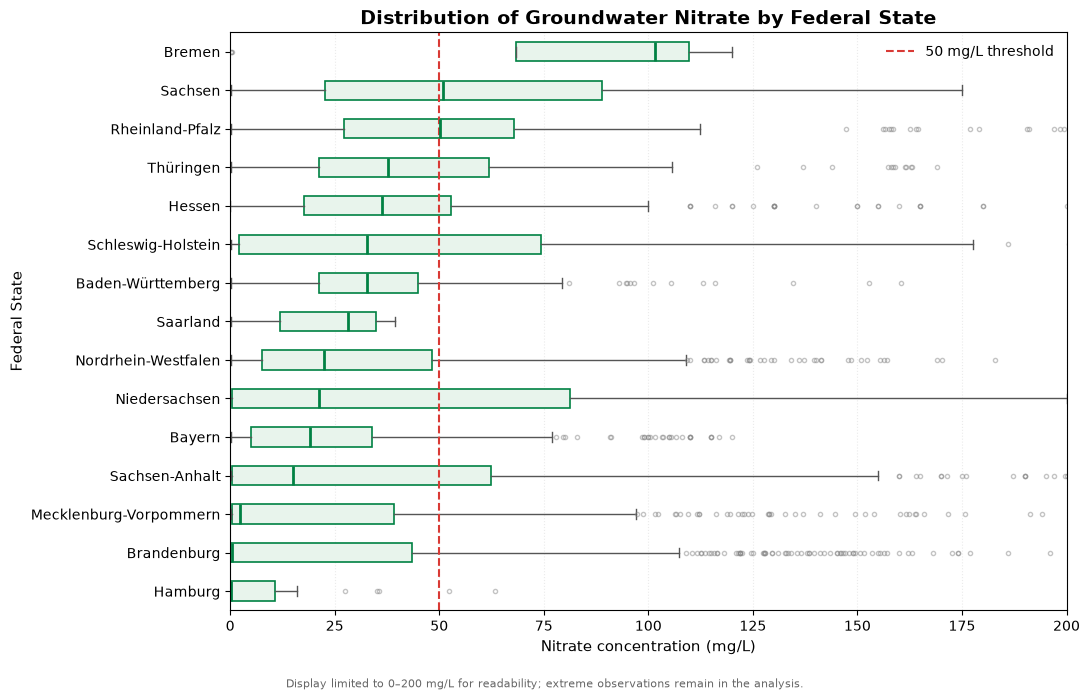

In [19]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# H2: Distribution of groundwater nitrate
# by German federal state
# --------------------------------------------------

# 1. Order federal states by median nitrate concentration
state_order = (
    df.groupby("FederalState")["Nitrate_mg_L"]
      .median()
      .sort_values(ascending=False)
      .index
)

# 2. Prepare nitrate values for each federal state
box_data = [
    df.loc[
        df["FederalState"] == state,
        "Nitrate_mg_L"
    ].dropna()
    for state in state_order
]

# 3. Create figure
plt.figure(figsize=(11, 7))

# 4. Create box plot
plt.boxplot(
    box_data,
    tick_labels=state_order,
    vert=False,
    showfliers=True,
    patch_artist=True,

    # Box design
    boxprops=dict(
        facecolor="#E8F4EC",
        edgecolor="#008143",
        linewidth=1.2
    ),

    # Median line
    medianprops=dict(
        color="#008143",
        linewidth=2
    ),

    # Whiskers
    whiskerprops=dict(
        color="#555555",
        linewidth=1
    ),

    # Whisker caps
    capprops=dict(
        color="#555555",
        linewidth=1
    ),

    # Outliers
    flierprops=dict(
        marker="o",
        markersize=3,
        markerfacecolor="none",
        markeredgecolor="#888888",
        alpha=0.5
    )
)

# 5. Add the 50 mg/L nitrate threshold
plt.axvline(
    x=50,
    color="#D93A35",
    linestyle="--",
    linewidth=1.5,
    label="50 mg/L threshold"
)

# 6. Title and axis labels
plt.title(
    "Distribution of Groundwater Nitrate by Federal State",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Nitrate concentration (mg/L)",
    fontsize=11
)

plt.ylabel(
    "Federal State",
    fontsize=11
)

# 7. Limit displayed range for readability
# Extreme observations remain in the analysis
plt.xlim(0, 200)

# Highest median at the top
plt.gca().invert_yaxis()

# 8. Light vertical grid
plt.grid(
    axis="x",
    linestyle=":",
    alpha=0.25
)

# 9. Threshold legend
plt.legend(
    frameon=False,
    loc="upper right"
)

# 10. Small transparency note
plt.figtext(
    0.5,
    0.01,
    "Display limited to 0–200 mg/L for readability; extreme observations remain in the analysis.",
    ha="center",
    fontsize=8,
    color="#666666"
)

# 11. Optimize layout
plt.tight_layout(rect=[0, 0.035, 1, 1])

# 12. Save high-resolution figure
plt.savefig(
    "../figures/h2_nitrate_distribution_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

# 13. Display figure
plt.show()

## H3 — Change in Nitrate Exceedances Over Time

**Hypothesis:** The proportion of nitrate observations exceeding 50 mg/L decreased between 2012 and 2022.

In [ ]:
yearly_exceedance = (
    df_powerbi
    .groupby("Year")
    .agg(
        TotalObservations=("Nitrate_mg_L", "count"),
        Above50=("Nitrate_mg_L", lambda x: (x > 50).sum())
    )
)

yearly_exceedance["PercentAbove50"] = (
    yearly_exceedance["Above50"]
    / yearly_exceedance["TotalObservations"]
    * 100
)

yearly_exceedance.round(2)

,TotalObservations,Above50,PercentAbove50
Year,,,
2012,656,199,30.34
2013,677,200,29.54
2014,627,180,28.71
2015,649,184,28.35
2016,679,184,27.10
2017,669,175,26.16
2018,664,178,26.81
2019,628,157,25.00
2020,700,176,25.14


In [ ]:
# H3: Spearman correlation between year and percentage above 50 mg/L

years = yearly_exceedance.index.to_numpy()
percent_above50 = yearly_exceedance["PercentAbove50"].to_numpy()

rho, p_value_h3 = stats.spearmanr(years, percent_above50)

print("Spearman correlation (rho):", round(rho, 3))
print("p-value:", round(p_value_h3, 6))

if p_value_h3 < 0.05 and rho < 0:
    print("Result: Significant decreasing trend in observations above 50 mg/L.")
else:
    print("Result: No statistically significant decreasing trend detected.")

Spearman correlation (rho): -0.982
p-value: 0.0
Result: Significant decreasing trend in observations above 50 mg/L.


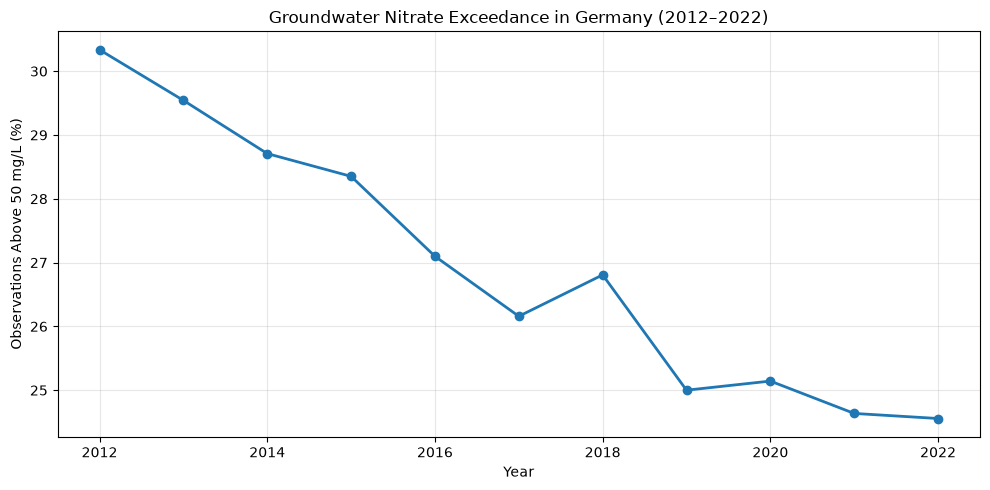

In [ ]:
# Visualization for H3

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_exceedance.index,
    yearly_exceedance["PercentAbove50"],
    marker="o",
    linewidth=2
)

plt.title(
    "Groundwater Nitrate Exceedance in Germany (2012–2022)"
)
plt.xlabel("Year")
plt.ylabel("Observations Above 50 mg/L (%)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

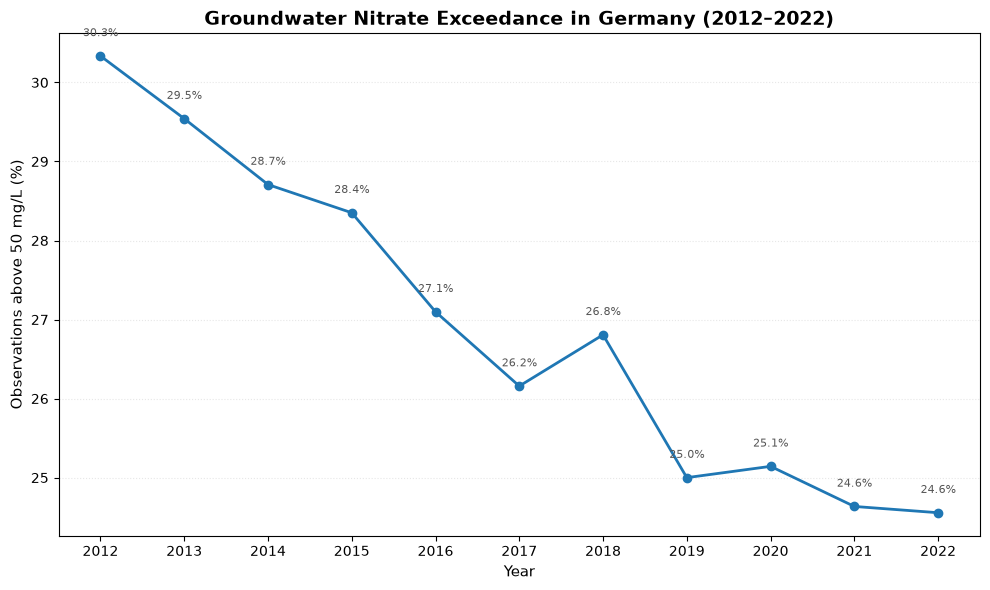

    Year  Exceedance_Percent
0   2012           30.335366
1   2013           29.542097
2   2014           28.708134
3   2015           28.351310
4   2016           27.098675
5   2017           26.158445
6   2018           26.807229
7   2019           25.000000
8   2020           25.142857
9   2021           24.635569
10  2022           24.556213


In [21]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# H3: Trend in nitrate threshold exceedances
# --------------------------------------------------

# Percentage of observations above 50 mg/L by year
exceedance_by_year = (
    df.groupby("Year")["Nitrate_mg_L"]
      .apply(lambda x: (x > 50).mean() * 100)
      .reset_index(name="Exceedance_Percent")
)

# Create figure
plt.figure(figsize=(10, 6))

# Plot annual exceedance percentage
plt.plot(
    exceedance_by_year["Year"],
    exceedance_by_year["Exceedance_Percent"],
    marker="o",
    linewidth=2,
    markersize=6,
    color="#1f77b4"
)

# Add values above the points
for year, value in zip(
    exceedance_by_year["Year"],
    exceedance_by_year["Exceedance_Percent"]
):
    plt.text(
        year,
        value + 0.25,
        f"{value:.1f}%",
        ha="center",
        fontsize=8,
        color="#555555"
    )

# Title and labels
plt.title(
    "Groundwater Nitrate Exceedance in Germany (2012–2022)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Year",
    fontsize=11
)

plt.ylabel(
    "Observations above 50 mg/L (%)",
    fontsize=11
)

# Show every year
plt.xticks(exceedance_by_year["Year"])

# Light grid for readability
plt.grid(
    axis="y",
    linestyle=":",
    alpha=0.3
)

# Clean appearance
plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "../figures/h3_nitrate_exceedance_trend.png",
    dpi=300,
    bbox_inches="tight"
)

# Display figure
plt.show()

# Print yearly percentages
print(exceedance_by_year)

## H4 — Relationship Between Sampling Depth and Nitrate Concentration

**Hypothesis:** Groundwater nitrate concentration is significantly associated with sampling depth.

A Spearman rank correlation is used to evaluate the relationship between sampling depth and nitrate concentration.
H4: Groundwater nitrate concentration is negatively associated with sampling depth.

H4 supported. There is a statistically significant but weak negative association between sampling depth and nitrate concentration (Spearman ρ = −0.169, p < 0.001).

In [ ]:
# H4: Sampling depth vs nitrate concentration

depth_data = df_powerbi[
    ["SamplingDepth_m", "Nitrate_mg_L"]
].dropna()

rho_h4, p_value_h4 = stats.spearmanr(
    depth_data["SamplingDepth_m"],
    depth_data["Nitrate_mg_L"]
)

print("Number of observations:", len(depth_data))
print("Spearman correlation (rho):", round(rho_h4, 3))
print("p-value:", p_value_h4)

if p_value_h4 < 0.05:
    print("Result: Significant association between sampling depth and nitrate concentration.")
else:
    print("Result: No statistically significant association detected.")

Number of observations: 7311
Spearman correlation (rho): -0.169
p-value: 6.474009688814441e-48
Result: Significant association between sampling depth and nitrate concentration.


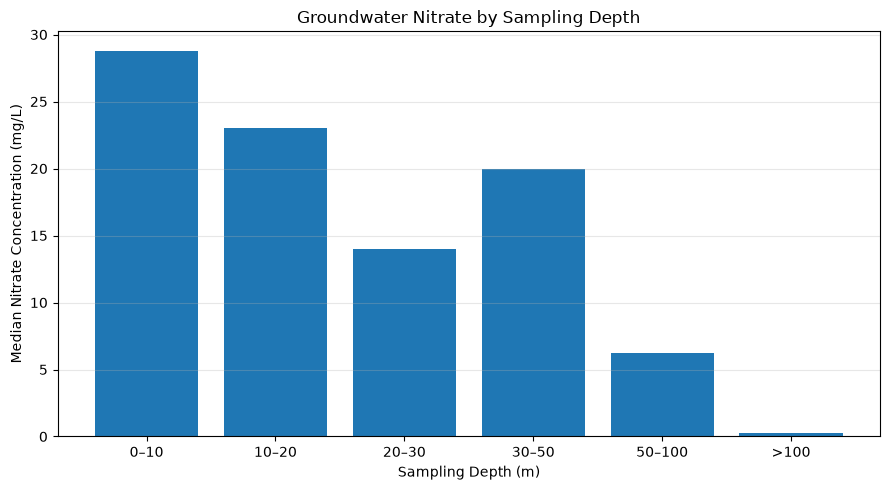

In [ ]:
# H4 visualization: nitrate concentration by sampling depth

depth_plot = depth_data.copy()

depth_plot["DepthGroup"] = pd.cut(
    depth_plot["SamplingDepth_m"],
    bins=[0, 10, 20, 30, 50, 100, float("inf")],
    labels=["0–10", "10–20", "20–30", "30–50", "50–100", ">100"],
    include_lowest=True
)

depth_summary = (
    depth_plot
    .groupby("DepthGroup", observed=True)["Nitrate_mg_L"]
    .median()
)

plt.figure(figsize=(9, 5))

plt.bar(
    depth_summary.index.astype(str),
    depth_summary.values
)

plt.title("Groundwater Nitrate by Sampling Depth")
plt.xlabel("Sampling Depth (m)")
plt.ylabel("Median Nitrate Concentration (mg/L)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

Nitrate concentrations tend to decrease with sampling depth, although the relationship is weak and not strictly linear (ρ = −0.169, p < 0.001).

## H5 — Persistent Nitrate Hotspots

**Hypothesis:** A subset of groundwater monitoring stations shows persistently elevated nitrate concentrations over multiple years.

A station is considered a persistent hotspot if it has observations in at least 5 years and exceeds 50 mg/L in at least 80% of observed years.

In [ ]:
station_persistence = (
    df_powerbi
    .groupby("StationCode")
    .agg(
        years_observed=("Year", "nunique"),
        years_above_50=("Nitrate_mg_L", lambda x: (x > 50).sum()),
        mean_nitrate=("Nitrate_mg_L", "mean"),
        max_nitrate=("Nitrate_mg_L", "max")
    )
)

station_persistence["exceedance_rate"] = (
    station_persistence["years_above_50"]
    / station_persistence["years_observed"]
    * 100
)

persistent_hotspots_h5 = station_persistence[
    (station_persistence["years_observed"] >= 5) &
    (station_persistence["exceedance_rate"] >= 80)
].sort_values(
    ["exceedance_rate", "mean_nitrate"],
    ascending=[False, False]
)

print("Persistent hotspots:", len(persistent_hotspots_h5))
print(
    "Share of all stations (%):",
    round(len(persistent_hotspots_h5) / station_persistence.shape[0] * 100, 2)
)

persistent_hotspots_h5.head(15)

Persistent hotspots: 157
Share of all stations (%): 20.47


,years_observed,years_above_50,mean_nitrate,max_nitrate,exceedance_rate
StationCode,,,,,
ST_37340030,5,5,328.900000,370.00,100.0
MV_26370007,10,10,327.415000,776.32,100.0
NW_080201570,11,11,250.390909,304.58,100.0
RP_2391181500,11,11,239.302727,299.50,100.0
NI_40507271,11,11,237.820909,337.12,100.0
MV_26510010,10,10,205.570000,245.43,100.0
NI_200001392,11,11,185.215455,230.20,100.0
BB_41476054,11,11,183.936364,284.50,100.0
RP_2395164700,11,11,183.181818,215.00,100.0


H5 supported. Using the predefined criterion (≥5 observed years and ≥80% exceedance rate), 157 monitoring stations (20.47%) were identified as persistent nitrate hotspots.

Nitrate pollution is improving over time → but substantial regional differences remain → exceedances are declining → deeper groundwater tends to have lower nitrate concentrations → yet persistent local hotspots remain.

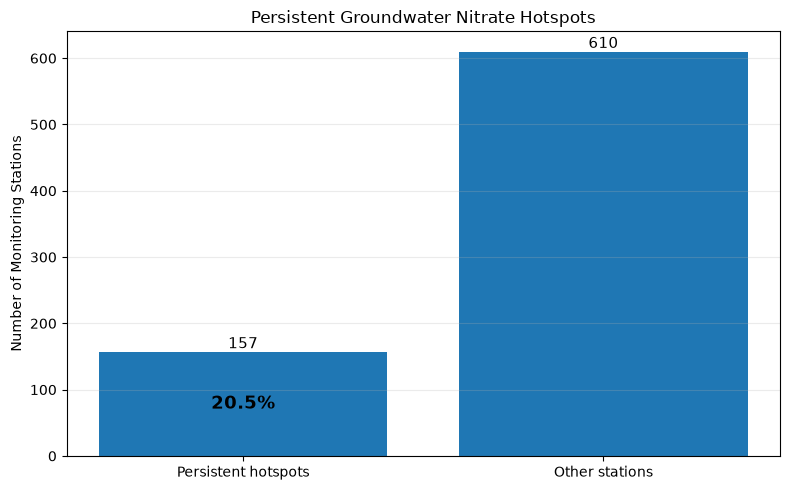

In [ ]:
# H5 visualization: persistent nitrate hotspots

total_stations = station_persistence.shape[0]
hotspot_count = len(persistent_hotspots_h5)
other_count = total_stations - hotspot_count

hotspot_share = hotspot_count / total_stations * 100

labels = ["Persistent hotspots", "Other stations"]
values = [hotspot_count, other_count]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.title("Persistent Groundwater Nitrate Hotspots")
plt.ylabel("Number of Monitoring Stations")

# Add values above bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.text(
    0,
    hotspot_count / 2,
    f"{hotspot_share:.1f}%",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.show()

# H5 visualization: persistent nitrate hotspots - 2 variante

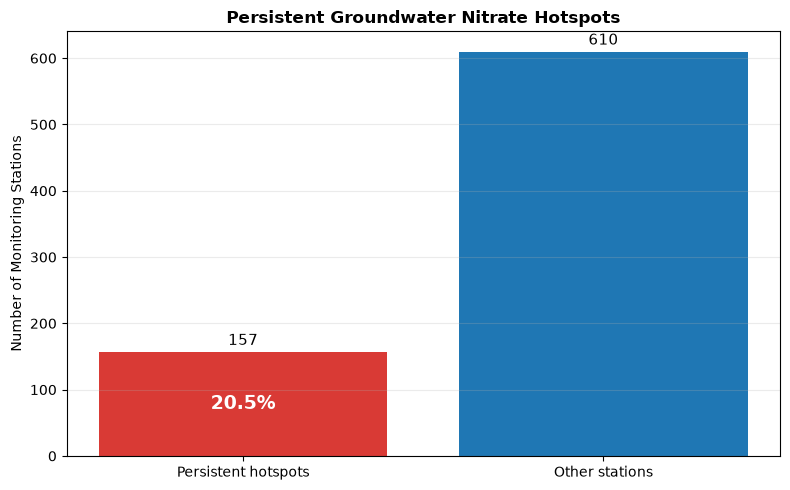

In [24]:
import matplotlib.pyplot as plt

# H5 results from the completed hotspot analysis
total_stations = 767
hotspot_count = 157
other_count = total_stations - hotspot_count

hotspot_share = hotspot_count / total_stations * 100

labels = ["Persistent hotspots", "Other stations"]
values = [hotspot_count, other_count]

plt.figure(figsize=(8, 5))

# Red = persistent hotspots, blue = other stations
bars = plt.bar(
    labels,
    values,
    color=["#D93A35", "#1f77b4"]
)

plt.title(
    "Persistent Groundwater Nitrate Hotspots",
    fontweight="bold"
)

plt.ylabel("Number of Monitoring Stations")

# Values above bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=11
    )

# Hotspot percentage inside the red bar
plt.text(
    0,
    hotspot_count / 2,
    f"{hotspot_share:.1f}%",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    color="white"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "../figures/h5_persistent_hotspots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Summary of Hypothesis Testing

Five hypotheses were evaluated to investigate temporal, spatial, and environmental patterns of groundwater nitrate concentrations in Germany between 2012 and 2022.

### H1 — Temporal Trend in Nitrate Concentration
**Hypothesis:** Average groundwater nitrate concentrations decreased between 2012 and 2022.

**Result:** Supported.

A significant decreasing temporal trend was identified, with an estimated decline of approximately **0.669 mg/L per year** (permutation test, **p = 0.0002**).

---

### H2 — Differences Between Federal States
**Hypothesis:** Groundwater nitrate concentrations differ significantly among German federal states.

**Result:** Supported.

The Kruskal–Wallis test showed statistically significant differences between federal states (**H = 713.414, p < 0.001**), indicating substantial regional variation in nitrate concentrations.

---

### H3 — Decline in the Proportion of Observations Above 50 mg/L
**Hypothesis:** The proportion of groundwater nitrate observations exceeding 50 mg/L decreased between 2012 and 2022.

**Result:** Supported.

The proportion decreased from **30.34% in 2012 to 24.56% in 2022**. A strong negative temporal association was detected (**Spearman rho = -0.982, p < 0.001**).

---

### H4 — Sampling Depth and Nitrate Concentration
**Hypothesis:** Groundwater nitrate concentration is negatively associated with sampling depth.

**Result:** Supported.

A statistically significant but weak negative association was detected between sampling depth and nitrate concentration (**Spearman rho = -0.169, p < 0.001**). Nitrate concentrations therefore tend to decrease with depth, although the relationship is not strong or strictly linear.

---

### H5 — Persistent Nitrate Hotspots
**Hypothesis:** A subset of monitoring stations shows persistently elevated nitrate concentrations over multiple years.

**Result:** Supported descriptively.

Using the predefined criterion of at least **5 observed years** and nitrate concentrations above **50 mg/L in at least 80% of observed years**, **157 stations (20.47% of stations in the analyzed dataset)** were identified as persistent nitrate hotspots.

---

## Overall Conclusion

Groundwater nitrate conditions in Germany show an overall improvement between 2012 and 2022. Both average nitrate concentrations and the proportion of observations exceeding the 50 mg/L threshold decreased significantly over time.

However, nitrate pollution remains spatially heterogeneous. Significant differences exist between federal states, and persistent high-nitrate monitoring stations remain present. Sampling depth is also associated with nitrate concentration, although this relationship is relatively weak.

These findings suggest that national improvements coexist with persistent regional and local groundwater nitrate challenges.